# Benchmark: count models on Long's bioChemists

Thirteen count models, scored on held-out rows of Long's biochemistry PhD article counts (`pscl::bioChemists`, n = 915) {cite:p}`long1990origins`. Every method sees the same 8 random 80/20 splits. The response is over-dispersed, and the mentor's article count is the strongest predictor. The comparison measures how nonlinear mean terms and the negative-binomial family change held-out loss and fitting cost on this small dataset.

This page reads a recorded artifact and refits nothing.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how thirteen count models score against each other on held-out bioChemists students |
| **Observed response** | `art`, articles in the last three years of the PhD (count, 0–19) |
| **Estimand** | mean held-out Poisson negative log-likelihood of the predicted mean; each family's own negative log-likelihood when it fits a size |
| **Units** | nats per held-out student |
| **Sampling unit** | one biochemistry PhD graduate |
| **Dependence** | treated as independent across students |
| **Split / resampling unit** | the student; the same 8 random 80/20 splits for every method |
| **Tuning** | `tune_mstop` (5-fold CV) for mboostrs; `gridsearch` for pyGAM; 400 rounds at learning rate 0.05 for the trees, plus one LightGBM arm with its round count chosen by 5-fold CV early stopping |
| **Uncertainty** | across-split standard errors, and paired per-split differences |
| **Claim type** | predictive comparison under the stated protocol on one small data set; not a statement about the libraries in general |
:::

In [1]:
from IPython.display import display
import altair as alt
import numpy as np
import polars as pl

from public_tasks import (
    failures, lines, load, memory, paired, protocol, summary, table, warnings_by_method,
)

bench, runs = load("count")
display(table(
    protocol(bench), stub="item", stubhead="Item",
    title="What was run", subtitle="Pinned source, shared splits, one thread per library",
    notes=["Source: bench_public_count.json, written by benches/bench_public_tasks.py."],
))

GT(_tbl_data=shape: (11, 2)
┌───────────────────────┬─────────────────────────────────┐
│ item                  ┆ value                           │
│ ---                   ┆ ---                             │
│ str                   ┆ str                             │
╞═══════════════════════╪═════════════════════════════════╡
│ source                ┆ https://raw.githubusercontent.… │
│ source sha256         ┆ cbb563e1191d757c…               │
│ train fraction        ┆ 0.8                             │
│ seeds (random splits) ┆ 8                               │
│ trees (fixed setting) ┆ 400 rounds, learning rate 0.05  │
│ …                     ┆ …                               │
│ versions              ┆ mboostrs 0.1.3, polars 2.0.0, … │
│ commit                ┆ 836c450c8c + uncommitted runne… │
│ runner sha256         ┆ ccd6242f4a5b001a…               │
│ measured at (UTC)     ┆ 2026-10-08T22:17:08+00:00       │
│ machine               ┆ Intel(R) Xeon(R) Processor, 8 … │
└───────────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10a34ee40>, _boxhead=Boxhead([ColInfo(var='item', type=<ColInfoTypeEnum.stub: 2>, column_label='item', column_align='left', column_width=None), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='value', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a595b20>, _spanners=Spanners([]), _heading=Heading(title='What was run', subtitle='Pinned source, shared splits, one thread per library', preheader=None), _stubhead='Item', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bb6e570>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109d0e0f0>, _source_notes=['Source: bench_public_count.json, written by benches/bench_public_tasks.py.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10a6bf800>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10bb2e9c0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_r

## The data

The mean is 1.69 articles, the variance 3.71, and 30% of students published nothing. A Poisson mean of 1.69 puts only 18% of its mass on zero; a Poisson model can add zeros only through variation in its mean between students, and the additive Poisson models below reach 21%–23%. The published analysis fits a negative binomial with gender, marriage, young children, department prestige and the mentor's own article count; the mentor term is the strongest and prestige is not significant once the others are in {cite:p}`long1997regression`.

## Held-out scores

Poisson negative log-likelihood (NLL) is computed for every method from its predicted mean, so all rows share one scale. The negative-binomial fits also report their own NB NLL, which scores the whole predictive distribution.

In [2]:
ORDER_KEY = pl.col("method").replace_strict({'pyGAM PoissonGAM': 0, 'mboostrs NBinomial': 1, 'mboostrs Poisson': 2, 'LightGBM (CV rounds)': 3, 'mboostrs autospec': 4, 'statsmodels Poisson': 5, 'sklearn PoissonRegressor': 6, 'statsmodels NB2': 7, 'mboostrs suggest_terms': 8, 'CatBoost': 9, 'XGBoost': 10, 'LightGBM': 11, 'sklearn HGB': 12}, default=99)
scores = (summary(runs, ["poisson_nll", "own_nll", "mae", "zero_share_predicted"])
          .with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"))
display(table(
    scores.select("method", "poisson_nll", "poisson_nll_se", "own_nll", "mae",
                  "zero_share_predicted", "failed", "seconds"),
    stub="method", stubhead="Method",
    title="Held-out scores on bioChemists",
    subtitle="Mean over 8 shared 80/20 splits of 915 students",
    labels={"poisson_nll": "Poisson NLL ↓", "poisson_nll_se": "± SE", "own_nll": "own NLL ↓",
            "mae": "MAE ↓", "zero_share_predicted": "P(0)", "failed": "failed", "seconds": "s"},
    better={"poisson_nll": "min", "own_nll": "min", "mae": "min", "zero_share_predicted": 0.3022},
    formats={"poisson_nll_se": 3, "seconds": 2}, decimals=3,
    notes=["own NLL is the NB negative log-likelihood for the NB fits and equals the Poisson NLL "
           "otherwise. P(0) is the mean predicted probability of zero articles; the held-out "
           "share is 0.30, and the bold P(0) is the closest to it. s is the median "
           "seconds for the whole workflow (tuning, fit, predict). failed counts seeds that raised."],
))

GT(_tbl_data=shape: (13, 8)
┌──────────────┬─────────────┬─────────────┬──────────┬──────────┬─────────────┬────────┬──────────┐
│ method       ┆ poisson_nll ┆ poisson_nll ┆ own_nll  ┆ mae      ┆ zero_share_ ┆ failed ┆ seconds  │
│ ---          ┆ ---         ┆ _se         ┆ ---      ┆ ---      ┆ predicted   ┆ ---    ┆ ---      │
│ str          ┆ f64         ┆ ---         ┆ f64      ┆ f64      ┆ ---         ┆ u32    ┆ f64      │
│              ┆             ┆ f64         ┆          ┆          ┆ f64         ┆        ┆          │
╞══════════════╪═════════════╪═════════════╪══════════╪══════════╪═════════════╪════════╪══════════╡
│ pyGAM        ┆ 1.792119    ┆ 0.026843    ┆ 1.792119 ┆ 1.308005 ┆ 0.234588    ┆ 0      ┆ 0.192523 │
│ PoissonGAM   ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ mboostrs     ┆ 1.798539    ┆ 0.02234     ┆ 1.708967 ┆ 1.320726 ┆ 0.300711    ┆ 0      ┆ 0.154923 │
│ NBinomial    ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ mboostrs     ┆ 1.799711    ┆ 0.022551    ┆ 1.799711 ┆ 1.325328 ┆ 0.21159     ┆ 0      ┆ 0.032526 │
│ Poisson      ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ LightGBM (CV ┆ 1.812287    ┆ 0.023372    ┆ 1.812287 ┆ 1.322411 ┆ 0.216475    ┆ 0      ┆ 0.08749  │
│ rounds)      ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ mboostrs     ┆ 1.812651    ┆ 0.024579    ┆ 1.715791 ┆ 1.32821  ┆ 0.299949    ┆ 1      ┆ 7.712781 │
│ autospec     ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ …            ┆ …           ┆ …           ┆ …        ┆ …        ┆ …           ┆ …      ┆ …        │
│ mboostrs sug ┆ 1.81677     ┆ 0.018741    ┆ 1.81677  ┆ 1.339446 ┆ 0.211745    ┆ 1      ┆ 0.036415 │
│ gest_terms   ┆             ┆             ┆          ┆          ┆             ┆        ┆          │
│ CatBoost     ┆ 1.840894    ┆ 0.024591    ┆ 1.840894 ┆ 1.323821 ┆ 0.251969    ┆ 0      ┆ 0.125442 │
│ XGBoost      ┆ 1.859489    ┆ 0.026485    ┆ 1.859489 ┆ 1.327219 ┆ 0.256868    ┆ 0      ┆ 0.054001 │
│ LightGBM     ┆ 1.874448    ┆ 0.02933     ┆ 1.874448 ┆ 1.345198 ┆ 0.266703    ┆ 0      ┆ 0.052789 │
│ sklearn HGB  ┆ 1.959719    ┆ 0.034414    ┆ 1.959719 ┆ 1.389124 ┆ 0.298542    ┆ 0      ┆ 0.330796 │
└──────────────┴─────────────┴─────────────┴──────────┴──────────┴─────────────┴────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x109d0e0f0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='poisson_nll', type=<ColInfoTypeEnum.default: 1>, column_label='Poisson NLL ↓', column_align='right', column_width=None), ColInfo(var='poisson_nll_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None), ColInfo(var='own_nll', type=<ColInfoTypeEnum.default: 1>, column_label='own NLL ↓', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE ↓', column_align='right', column_width=None), ColInfo(var='zero_share_predicted', type=<ColInfoTypeEnum.default: 1>, column_label='P(0)', column_align='right', column_width=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='failed', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a32b860>, _spanners=Spanners([]), _heading=Heading(title='Held-out scores on bioChemists', subtitle='Mean over 8 shared 80/20 splits of 915 students', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bbbf9e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a34ee40>, _source_notes=['own NLL is the NB negative log-likelihood for the NB fits and equal

**Negative-binomial dispersion improves the predicted zero frequency.** On the
Poisson scale, mboostrs NBinomial and mboostrs Poisson are
0.001 nats apart (paired SE 0.001): the two mean models are almost
the same. On its own likelihood the negative-binomial (NB) fit scores 1.709
against 1.800, and its predicted share of zeros,
0.30, matches the held-out
0.30, where the additive Poisson models sit between 0.21 and
0.23. The fixed-round trees predict more zeros
(0.25–0.30) only because their means spread further
between students, and they score worse for it.
The statsmodels negative-binomial (NB2) fit shows the same split (1.712 own, 1.813 Poisson).
Anyone who needs the probability of no articles should choose the family
first; the mean model matters much less.

**The smooth additive models are ahead of the GLM, by one to two standard errors.**
mboostrs Poisson is 0.013 nats better than the statsmodels Poisson GLM
(paired SE 0.012), which 8 splits do not resolve. pyGAM's PoissonGAM is
0.021 better than the GLM (SE 0.010) and 0.008 better than
mboostrs (SE 0.013): its lead over the GLM is the clearer of the two, its lead
over mboostrs is not resolved. The source of
the gain is visible in the mentor effect below: the GLM has to fit a single
slope through a curve that is steep in the bulk and flat in the tail.

**Fixed-round trees overfit 732 training rows; tuned rounds remove the gap.** At 400 rounds and learning rate 0.05 the four tree libraries score between 1.841 and 1.960. The same LightGBM with its round count chosen by 5-fold early stopping on the training rows (39–113 rounds across splits) scores 1.812, level with the GLM. With five predictors and no strong interaction there is little for trees to find that an additive model misses; the fixed-setting rows measure over-fitting, not the function class.

In [3]:
display(table(
    paired(runs, "poisson_nll", "statsmodels Poisson").with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Paired difference from the Poisson GLM",
    subtitle="Mean over splits of (method − statsmodels Poisson) Poisson NLL; negative is better",
    labels={"pairs": "splits", "difference": "Δ NLL", "difference_se": "± SE"},
    better={"difference": "min"}, decimals=3,
    notes=["Pairs are the splits on which both the method and the GLM finished. The SE is the "
           "standard deviation of the per-split difference over the square root of the pairs."],
))

GT(_tbl_data=shape: (12, 4)
┌────────────────────────┬───────┬────────────┬───────────────┐
│ method                 ┆ pairs ┆ difference ┆ difference_se │
│ ---                    ┆ ---   ┆ ---        ┆ ---           │
│ str                    ┆ u32   ┆ f64        ┆ f64           │
╞════════════════════════╪═══════╪════════════╪═══════════════╡
│ pyGAM PoissonGAM       ┆ 8     ┆ -0.020622  ┆ 0.009516      │
│ mboostrs NBinomial     ┆ 8     ┆ -0.014201  ┆ 0.012161      │
│ mboostrs Poisson       ┆ 8     ┆ -0.013029  ┆ 0.01197       │
│ LightGBM (CV rounds)   ┆ 8     ┆ -0.000454  ┆ 0.010795      │
│ mboostrs autospec      ┆ 7     ┆ -0.01574   ┆ 0.014545      │
│ …                      ┆ …     ┆ …          ┆ …             │
│ mboostrs suggest_terms ┆ 7     ┆ -0.011621  ┆ 0.014454      │
│ CatBoost               ┆ 8     ┆ 0.028153   ┆ 0.020287      │
│ XGBoost                ┆ 8     ┆ 0.046749   ┆ 0.016138      │
│ LightGBM               ┆ 8     ┆ 0.061708   ┆ 0.019562      │
│ sklearn HGB            ┆ 8     ┆ 0.146979   ┆ 0.026859      │
└────────────────────────┴───────┴────────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x109d0e0f0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='pairs', type=<ColInfoTypeEnum.default: 1>, column_label='splits', column_align='right', column_width=None), ColInfo(var='difference', type=<ColInfoTypeEnum.default: 1>, column_label='Δ NLL', column_align='right', column_width=None), ColInfo(var='difference_se', type=<ColInfoTypeEnum.default: 1>, column_label='± SE', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a34ee40>, _spanners=Spanners([]), _heading=Heading(title='Paired difference from the Poisson GLM', subtitle='Mean over splits of (method − statsmodels Poisson) Poisson NLL; negative is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bbbfa70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bbbf9e0>, _source_notes=['Pairs are the splits on which both the method and the GLM finished. The SE is the standard deviation of the per-split difference over the square root of the pairs.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='pairs', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='pairs', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='pairs', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='pairs', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='difference', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='difference', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='difference', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BC11D60>, mask=None), grpname=None, colname='difference', rownum=7, colnum=None, st

(the-mentor-effect-why-an-additive-smooth-helps)=
## Mentor article-count effect

The curve is the mboostrs NBinomial partial effect of the mentor's article count (`ment`) on the log-mean, fitted on all 915 students at the number of boosting steps chosen by cross-validation (`mstop`); the straight line is the Poisson GLM's slope (0.026 per article) through the sample mean. Both are centred on the sample. The smooth rises about 0.043 per article between 0 and 20 — steeper than the GLM — and 0.020 per article between 20 and 40. Only 1.7% of mentors published more than 40 articles; above that the smooth turns down on very few students and should not be read as a finding. The GLM's single slope is too shallow where most students are, which is the likeliest source of the held-out gain.

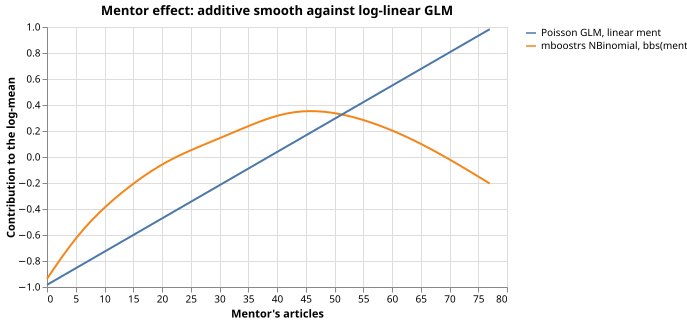

In [4]:
ev = bench["evidence"]
grid = np.asarray(ev["ment_grid"])
smooth = np.asarray(ev["ment_effect_mboostrs"])
smooth = smooth - smooth.mean()
line = ev["ment_slope_glm"] * (grid - ev["ment_mean"])
line = line - line.mean()
curves = pl.concat([
    pl.DataFrame({"ment": grid, "effect": smooth, "model": "mboostrs NBinomial, bbs(ment)"}),
    pl.DataFrame({"ment": grid, "effect": line, "model": "Poisson GLM, linear ment"}),
])
alt.Chart(curves).mark_line(strokeWidth=2).encode(
    x=alt.X("ment:Q", title="Mentor's articles"),
    y=alt.Y("effect:Q", title="Contribution to the log-mean"),
    color=alt.Color("model:N", title=None),
).properties(width=460, height=260, title="Mentor effect: additive smooth against log-linear GLM")

## Tuning, failures and cost

`tune_mstop` chose between 7 and 92 steps for mboostrs Poisson across the splits. Five folds of about 590 rows locate the minimum of the risk curve only roughly, so the step count is noisy from split to split. The held-out score does not follow it in a simple way: the rank correlation between chosen `mstop` and held-out NLL across the 8 splits is +0.12. Read the step count as a rough setting, not a property of the data.

`suggest_terms` (which types each predictor) and `autospec` (the automatic specification search) each failed on one split. Their typing of the predictors changes from split to split: on some splits `ment` becomes a `brandom` group term (a random effect with one coefficient per group level) instead of a smooth, and on the failing split a held-out student's mentor had a count no training row had, so `predict` refused the unseen level. The hand-written formulas use `bbs(ment)` and cannot fail this way. `autospec` chose the negative binomial on every split it finished, consistent with the observed overdispersion. It costs a median 7.7 s against 0.03 s for the hand-written mboostrs model and scores no better.

In [5]:
ORDER_KEY = pl.col("method").replace_strict({'pyGAM PoissonGAM': 0, 'mboostrs NBinomial': 1, 'mboostrs Poisson': 2, 'LightGBM (CV rounds)': 3, 'mboostrs autospec': 4, 'statsmodels Poisson': 5, 'sklearn PoissonRegressor': 6, 'statsmodels NB2': 7, 'mboostrs suggest_terms': 8, 'CatBoost': 9, 'XGBoost': 10, 'LightGBM': 11, 'sklearn HGB': 12}, default=99)
fails = failures(runs)
display(table(
    fails if fails.height else pl.DataFrame({"method": ["(none)"], "seed": [None], "error": [""]}),
    stub="method", stubhead="Method",
    title="Failed fits", subtitle="Each unsuccessful (method, seed) with the first line of its error",
    notes=["A failed seed is excluded from that method's means and counted in its failed column."],
))

GT(_tbl_data=shape: (2, 4)
┌────────────────────────┬─────────┬──────┬─────────────────────────────────┐
│ method                 ┆ variant ┆ seed ┆ error                           │
│ ---                    ┆ ---     ┆ ---  ┆ ---                             │
│ str                    ┆ null    ┆ i64  ┆ str                             │
╞════════════════════════╪═════════╪══════╪═════════════════════════════════╡
│ mboostrs suggest_terms ┆ null    ┆ 7    ┆ MboostrsValueError: unknown Br… │
│ mboostrs autospec      ┆ null    ┆ 7    ┆ MboostrsValueError: unknown Br… │
└────────────────────────┴─────────┴──────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10a595b20>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='variant', type=<ColInfoTypeEnum.default: 1>, column_label='variant', column_align='center', column_width=None), ColInfo(var='seed', type=<ColInfoTypeEnum.default: 1>, column_label='seed', column_align='right', column_width=None), ColInfo(var='error', type=<ColInfoTypeEnum.default: 1>, column_label='error', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a11fb60>, _spanners=Spanners([]), _heading=Heading(title='Failed fits', subtitle='Each unsuccessful (method, seed) with the first line of its error', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bc77890>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10a32b7d0>, _source_notes=["A failed seed is excluded from that method's means and counted in its failed column."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='variant', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='variant', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='seed', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='seed', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='error', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC950>, mask=None), grpname=None, colname='error', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10bbbfa70>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10bc77ce0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'S

In [6]:
display(table(
    memory(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Peak memory of one fit",
    subtitle="Fresh process, seed 0: VmHWM after the fit minus VmRSS before it",
    labels={"seconds": "s", "peak_rss_growth_mb": "Δ RSS MB", "status": "status"},
    better={"peak_rss_growth_mb": "min"}, formats={"seconds": 2, "peak_rss_growth_mb": 1},
    notes=["The high-water mark is reset after imports and data loading, so the figure is the "
           "fit's own growth. One probe per method; descriptive, not averaged."],
))

GT(_tbl_data=shape: (13, 4)
┌────────────────────────┬──────────┬────────────────────┬─────────┐
│ method                 ┆ seconds  ┆ peak_rss_growth_mb ┆ status  │
│ ---                    ┆ ---      ┆ ---                ┆ ---     │
│ str                    ┆ f64      ┆ f64                ┆ str     │
╞════════════════════════╪══════════╪════════════════════╪═════════╡
│ pyGAM PoissonGAM       ┆ 0.187065 ┆ 8.628906           ┆ success │
│ mboostrs NBinomial     ┆ 0.154346 ┆ 8.214844           ┆ success │
│ mboostrs Poisson       ┆ 0.033081 ┆ 8.027344           ┆ success │
│ LightGBM (CV rounds)   ┆ 0.100724 ┆ 7.2890625          ┆ success │
│ mboostrs autospec      ┆ 7.87373  ┆ 21.570312          ┆ success │
│ …                      ┆ …        ┆ …                  ┆ …       │
│ mboostrs suggest_terms ┆ 0.051185 ┆ 8.574219           ┆ success │
│ CatBoost               ┆ 0.186757 ┆ 11.019531          ┆ success │
│ XGBoost                ┆ 0.061076 ┆ 10.007812          ┆ success │
│ LightGBM               ┆ 0.062814 ┆ 8.125              ┆ success │
│ sklearn HGB            ┆ 0.391072 ┆ 3.796875           ┆ success │
└────────────────────────┴──────────┴────────────────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10bc773e0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None), ColInfo(var='peak_rss_growth_mb', type=<ColInfoTypeEnum.default: 1>, column_label='Δ RSS MB', column_align='right', column_width=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bc13860>, _spanners=Spanners([]), _heading=Heading(title='Peak memory of one fit', subtitle='Fresh process, seed 0: VmHWM after the fit minus VmRSS before it', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bcacb60>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bcace00>, _source_notes=["The high-water mark is reset after imports and data loading, so the figure is the fit's own growth. One probe per method; descriptive, not averaged."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='seconds', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='seconds', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='seconds', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='seconds', rownum=8, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mask=None), grpname=None, colname='peak_rss_growth_mb', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x109D0E0F0>, mas

In [7]:
display(table(
    warnings_by_method(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Warnings raised during the fits",
    subtitle="Distinct warning texts across all seeds, with one example",
    labels={"distinct_warnings": "distinct", "example": "example"},
    notes=["Methods that raised none are omitted."],
))
display(table(
    lines(bench).with_columns(ORDER_KEY.alias("o")).sort("o").drop("o"),
    stub="method", stubhead="Method",
    title="Lines of code per method",
    subtitle="Statements in each method's function in benches/bench_public_tasks.py",
    labels={"lines": "lines"},
    notes=["Docstrings, comments and blank lines are not counted. Shared helpers are not "
           "counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds "
           "row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal."],
))

GT(_tbl_data=shape: (5, 3)
┌────────────────────────┬───────────────────┬─────────────────────────────────┐
│ method                 ┆ distinct_warnings ┆ example                         │
│ ---                    ┆ ---               ┆ ---                             │
│ str                    ┆ i64               ┆ str                             │
╞════════════════════════╪═══════════════════╪═════════════════════════════════╡
│ pyGAM PoissonGAM       ┆ 1                 ┆ DeprecationWarning: Bitwise in… │
│ mboostrs NBinomial     ┆ 2                 ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs Poisson       ┆ 1                 ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs autospec      ┆ 6                 ┆ ExtrapolationWarning: 1 learne… │
│ mboostrs suggest_terms ┆ 1                 ┆ ExtrapolationWarning: 1 learne… │
└────────────────────────┴───────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10bbbfa70>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='distinct_warnings', type=<ColInfoTypeEnum.default: 1>, column_label='distinct', column_align='right', column_width=None), ColInfo(var='example', type=<ColInfoTypeEnum.default: 1>, column_label='example', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10bc13860>, _spanners=Spanners([]), _heading=Heading(title='Warnings raised during the fits', subtitle='Distinct warning texts across all seeds, with one example', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bcace00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bcacfe0>, _source_notes=['Methods that raised none are omitted.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='distinct_warnings', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='distinct_warnings', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='distinct_warnings', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='distinct_warnings', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='example', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='example', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='example', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAC8C0>, mask=None), grpname=None, colname='example', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10bcac800>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10bcac9b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, 

GT(_tbl_data=shape: (13, 2)
┌────────────────────────┬───────┐
│ method                 ┆ lines │
│ ---                    ┆ ---   │
│ str                    ┆ i64   │
╞════════════════════════╪═══════╡
│ pyGAM PoissonGAM       ┆ 4     │
│ mboostrs NBinomial     ┆ 6     │
│ mboostrs Poisson       ┆ 6     │
│ LightGBM (CV rounds)   ┆ 2     │
│ mboostrs autospec      ┆ 6     │
│ …                      ┆ …     │
│ mboostrs suggest_terms ┆ 6     │
│ CatBoost               ┆ 2     │
│ XGBoost                ┆ 2     │
│ LightGBM               ┆ 2     │
│ sklearn HGB            ┆ 2     │
└────────────────────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10bcac800>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a595b20>, _spanners=Spanners([]), _heading=Heading(title='Lines of code per method', subtitle="Statements in each method's function in benches/bench_public_tasks.py", preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10bcac8c0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10bcad6a0>, _source_notes=['Docstrings, comments and blank lines are not counted. Shared helpers are not counted either: the tree rows hide a settings helper (tree_model) and the CV-rounds row hides a 9-line lightgbm.cv wrapper. Treat this as a rough ergonomics signal.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAD550>, mask=None), grpname=None, colname='lines', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAD550>, mask=None), grpname=None, colname='lines', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAD550>, mask=None), grpname=None, colname='lines', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10BCAD550>, mask=None), grpname=None, colname='lines', rownum=8, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x10bcacfb0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10bcacd70>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, c

## Reproduction

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1 \
  python benches/bench_public_tasks.py --task count \
  --out docs/book/benchmarks/bench_public_count.json
```

The results file `bench_public_count.json` records the source URL and sha256, the seeds, the tree settings, the thread environment, library versions, the runner's sha256, the commit and the machine.